In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")


Libraries imported successfully.


In [6]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns = data.feature_names)
y = pd.Series(data.target)

df = X.copy()
df["target"] = y

print("Data loaded successfully.")
print("Daatset shape:", df.shape)

df.head()

Data loaded successfully.
Daatset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [7]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nTarget classes:")
print(data.target_names)

print("\nTarget distribution:")
print(y.value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

In [8]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())



Missing values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Duplicate rows:
0


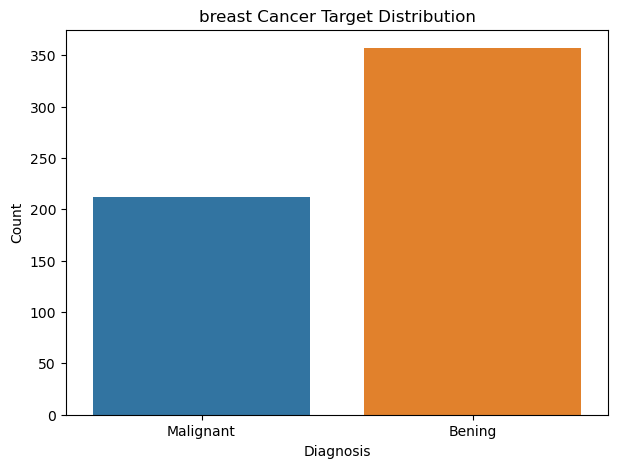

In [9]:
plt.figure(figsize = (7, 5))
sns.countplot(x = y.map({0: "Malignant", 1: "Bening"}))

plt.title("breast Cancer Target Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()



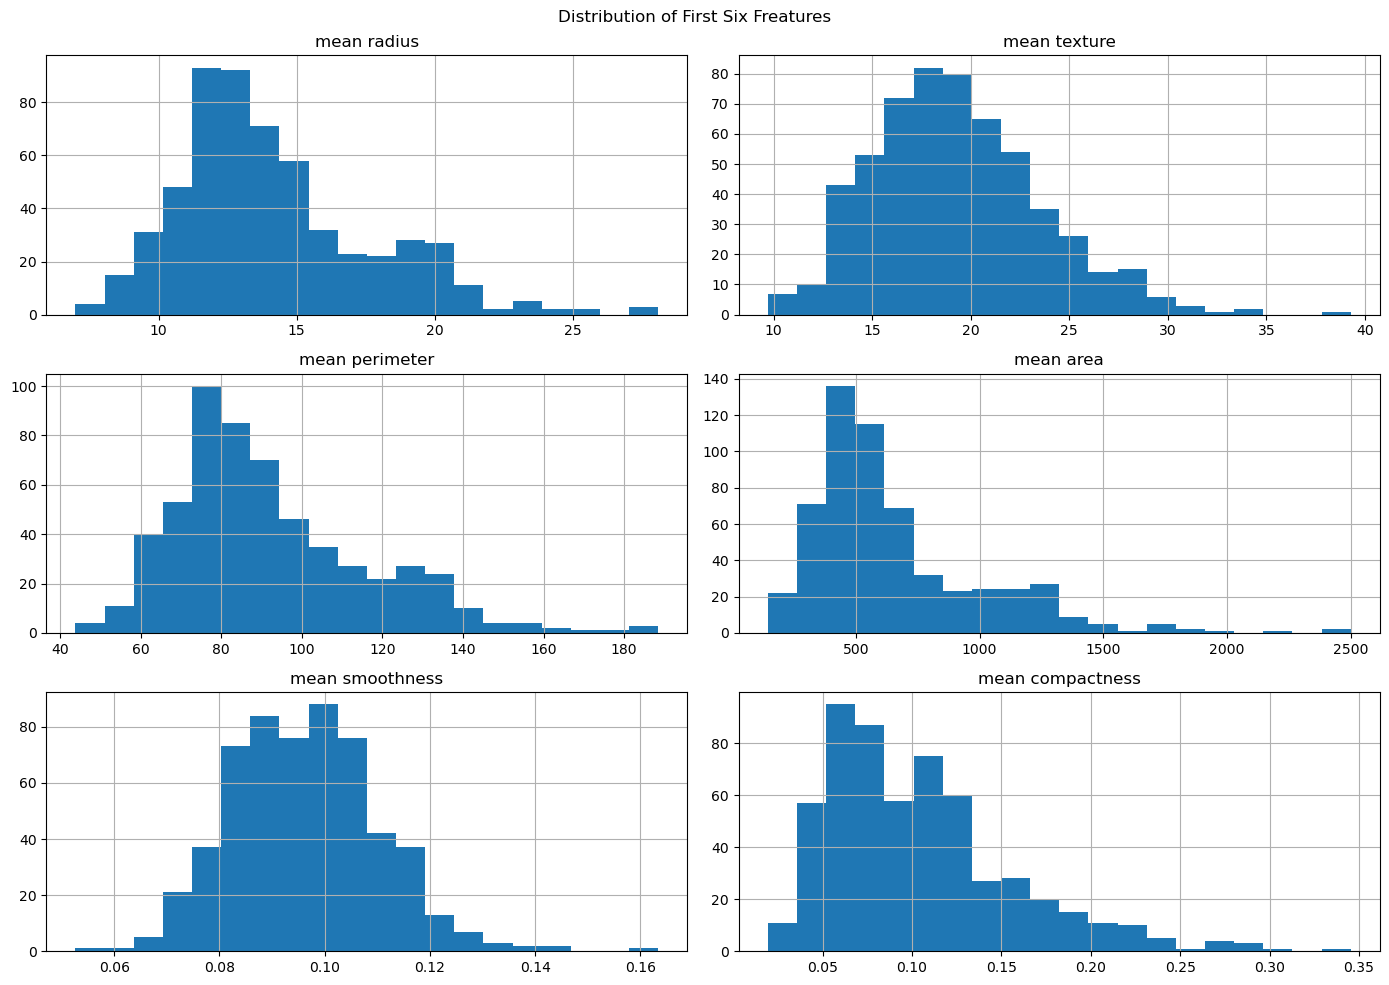

In [10]:
df.iloc[:, :6].hist(figsize= (14, 10), bins = 20)
plt.suptitle("Distribution of First Six Freatures")
plt.tight_layout()
plt.show()

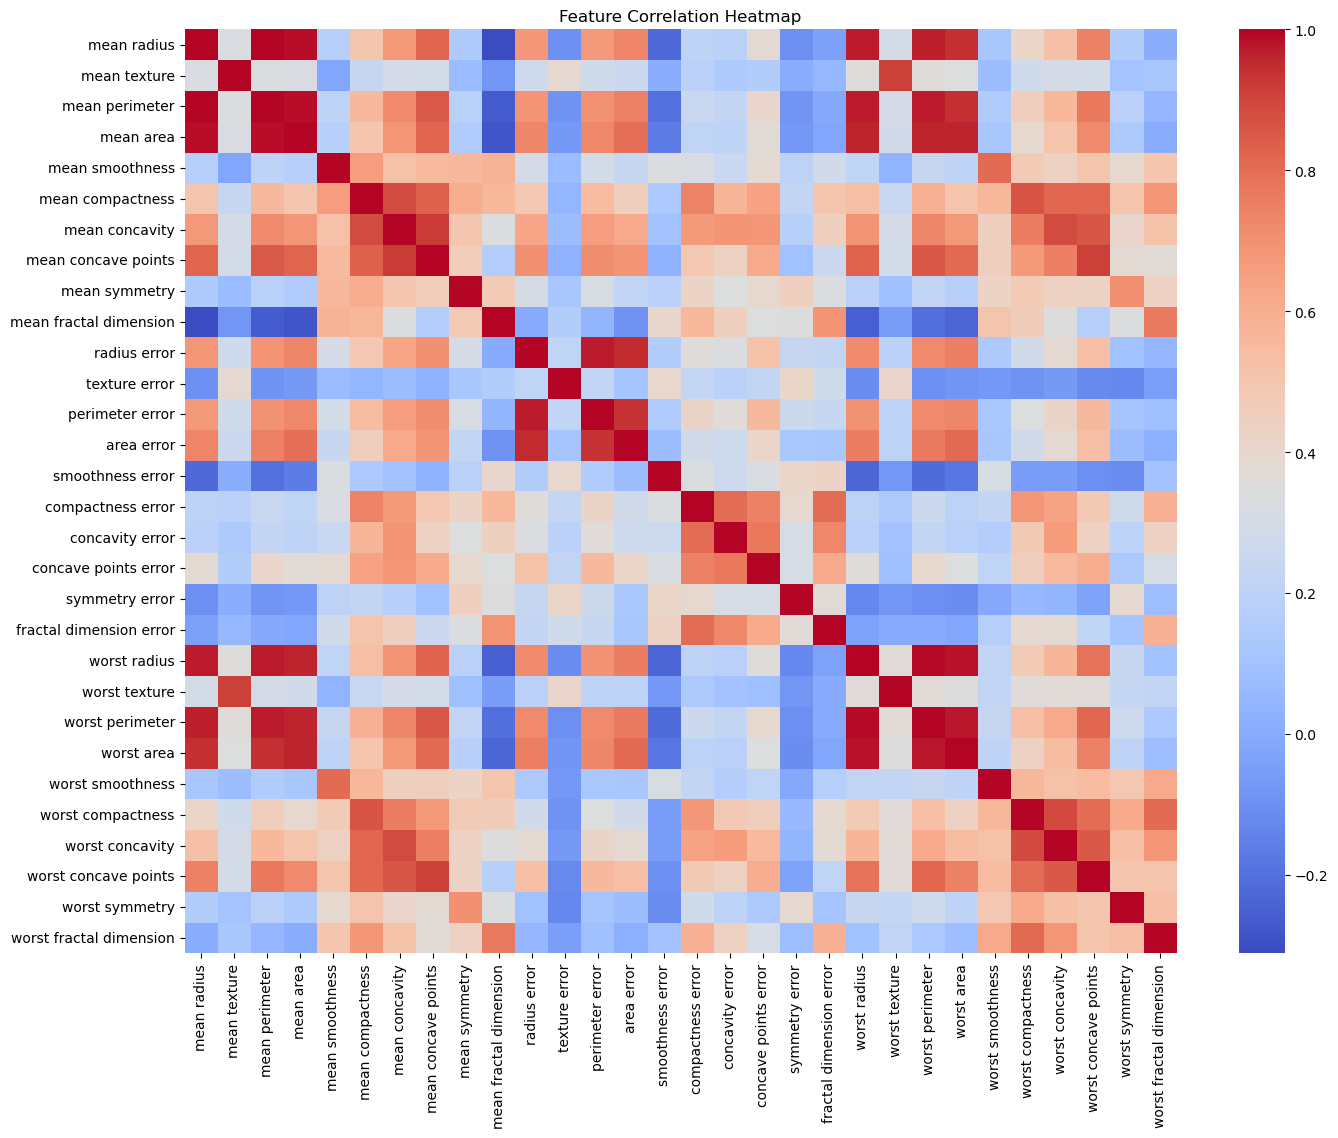

In [12]:
plt.figure(figsize=(16, 12))
correlation = X.corr()
sns.heatmap(correlation, cmap = "coolwarm", annot = False)

plt.title("Feature Correlation Heatmap")
plt.show()


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

print("Training data:", X_train.shape, y_train.shape)
print("Testing data:", X_test.shape, y_test.shape)

Training data: (455, 30) (455,)
Testing data: (114, 30) (114,)


In [14]:
model = DecisionTreeClassifier(criterion = "gini", max_depth = 4, random_state = 42)
model.fit(X_train, y_train)
print("Model trained successfully.")


Model trained successfully.


In [15]:
y_pred = model.predict(X_test)
print("actual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

actual values:
[0 1 0 1 0 1 1 0 0 0]

Predicted values:
[0 1 0 1 0 1 1 0 0 0]
